         T      measured          R(T)
    2.0000      0.047831      0.047656
    4.1814      0.055259      0.055001
   10.0000      0.045408      0.045176


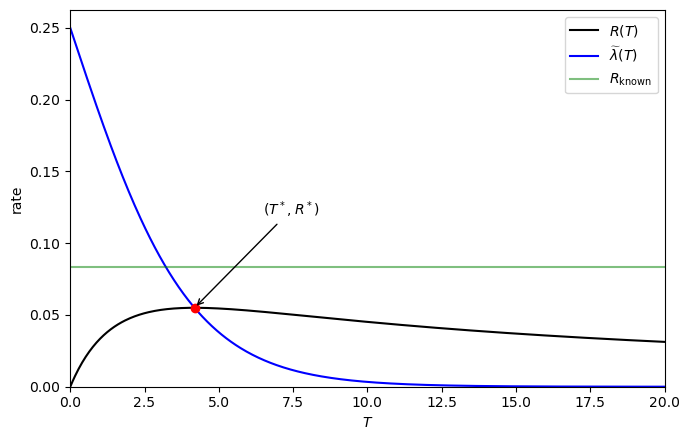

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

p_H = 0.5
rho = 0.5
tau = 5.0
n_visits = 400_000
rng = np.random.default_rng(2026)


def R(T):
    mean_food = p_H * (1 - np.exp(-rho * T))
    mean_time = mean_food / rho + (1 - p_H) * T + tau
    return mean_food / mean_time


def lambda_tilde(T):
    high_and_no_food = p_H * np.exp(-rho * T)
    prob_no_food = high_and_no_food + (1 - p_H)
    return rho * high_and_no_food / prob_no_food


T_star = brentq(lambda T: lambda_tilde(T) - R(T), 0, 10)
R_star = R(T_star)
R_known = p_H / (p_H / rho + tau)

is_high = rng.random(n_visits) < p_H

discovery_time = rng.exponential(scale=1 / rho, size=n_visits)
discovery_time[~is_high] = np.inf

print(f"{'T':>10}  {'measured':>12}  {' R(T)':>12}")
for T in [2.0, T_star, 10.0]:
    found_food = discovery_time <= T
    search_time = np.minimum(discovery_time, T)
    total_time = tau + search_time

    measured_rate = found_food.sum() / total_time.sum()
    print(f"{T:10.4f}  {measured_rate:12.6f}  {R(T):12.6f}")

T_values = np.linspace(0, 20, 500)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(T_values, R(T_values), color="black",label=r"$R(T)$")
ax.plot(T_values, lambda_tilde(T_values),color="blue", label=r"$\widetilde{\lambda}(T)$")
ax.axhline(R_known, color="green", alpha=0.5, label=r"$R_{\mathrm{known}}$")

ax.scatter(T_star, R_star, color="red", zorder=3)
ax.annotate(
    rf"$(T^*, R^*)$",
    xy=(T_star, R_star),
    xytext=(6.5, 0.12),
    arrowprops={"arrowstyle": "->"},
)

ax.set_xlabel(r"$T$")
ax.set_ylabel("rate")
ax.set_xlim(0, 20)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
plt.show()

(i)
range of x: [0.1628, 0.8082]
range of y: [0.1918, 0.8372]
Variation of K: 2.519e-10

(ii)

tau = 0
last quarter average (0.4246, 0.4559)
last quarter mean distance early 0.4239
last quarter mean distance late  0.6218

tau = 0.05
last quarter average (0.4609, 0.5144)
last quarter mean distance early 0.1742
last quarter mean distance late  0.1840


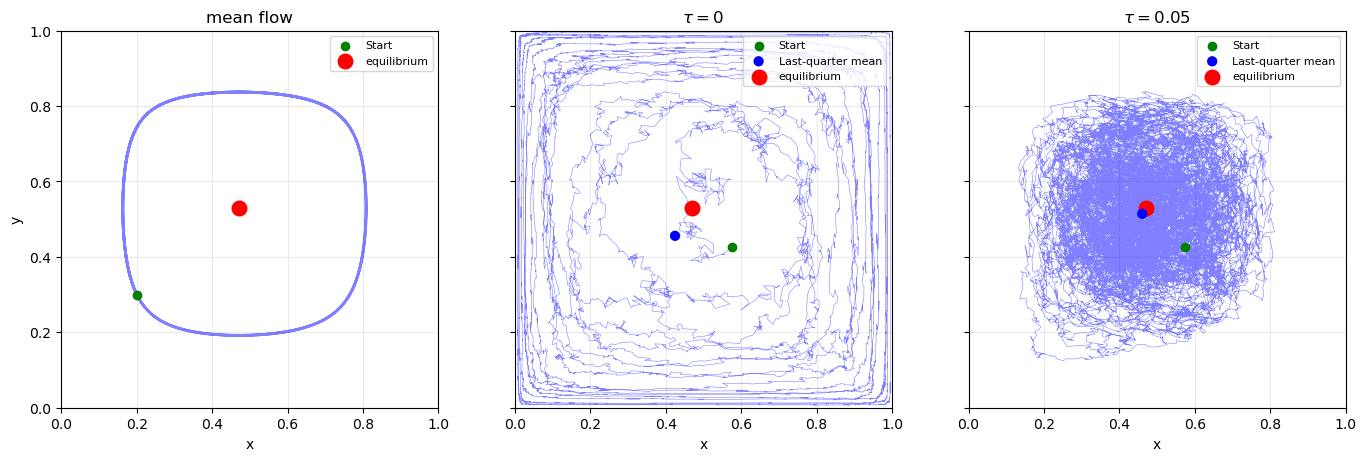

In [17]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp


x_star = 8.0 / 17.0
y_star = 9.0 / 17.0
eta = 0.02



def F_antideriv(s, c):
    return (
        (1.0 - 2.0 * c) * np.log(s / (1.0 - s))
        + c / s
        + (1.0 - c) / (1.0 - s)
    )


def K_func(x, y):
    kx = F_antideriv(x, x_star) - F_antideriv(x_star, x_star)
    ky = F_antideriv(y, y_star) - F_antideriv(y_star, y_star)
    return kx + ky


def mean_flow_ode(t, state):
    x, y = state
    dx = 0.85 * eta * (x * (1.0 - x))**2 * (y - y_star)
    dy = -0.85 * eta * (y * (1.0 - y))**2 * (x - x_star)
    return [dx, dy]


t_end = 20_000
t_grid = np.linspace(0, t_end, 10_000)

sol = solve_ivp(
    mean_flow_ode,
    t_span=(0, t_end),
    y0=[0.2, 0.3],
    t_eval=t_grid,
    method="DOP853",
    rtol=1e-11,
    atol=1e-13,
)

x_ode, y_ode = sol.y
K_ode = K_func(x_ode, y_ode)

print("(i)")
print(f"range of x: [{x_ode.min():.4f}, {x_ode.max():.4f}]")
print(f"range of y: [{y_ode.min():.4f}, {y_ode.max():.4f}]")
print(f"Variation of K: {np.ptp(K_ode):.3e}")


def simulate_game(tau, n_steps=400_000, seed=42):
    rng = random.Random(seed)
    p_make = (
        (0.60, 0.40),
        (0.25, 0.40),
    )

    theta1, theta2 = 0.3, -0.3
    baseline = 0.0

    xs = np.empty(n_steps)
    ys = np.empty(n_steps)

    for t in range(n_steps):
        x = 1.0 / (1.0 + math.exp(-theta1))
        y = 1.0 / (1.0 + math.exp(-theta2))
        xs[t] = x
        ys[t] = y

        a1 = int(rng.random() < x)
        a2 = int(rng.random() < y)

        shot_value = 2 + a1
        made_shot = rng.random() < p_make[a1][a2]
        reward = shot_value if made_shot else 0.0

        advantage = reward - baseline

        theta1 += eta * (
            advantage * (a1 - x)
            - tau * theta1 * x * (1.0 - x)
        )
        theta2 += eta * (
            -advantage * (a2 - y)
            - tau * theta2 * y * (1.0 - y)
        )

        baseline += advantage / (t + 1)

    return xs, ys


fig, axes = plt.subplots(
    1, 3, figsize=(14, 4.5), sharex=True, sharey=True,
    constrained_layout=True,
)

axes[0].plot(x_ode, y_ode, color="blue", alpha=0.5, lw=2)
axes[0].scatter(x_ode[0], y_ode[0], color="green", label="Start", zorder=3)
axes[0].set_title("mean flow")

print("\n(ii)")

for ax, tau in zip(axes[1:], [0.0, 0.05]):
    xs, ys = simulate_game(tau)
    q = len(xs) // 4

    distance = np.sqrt((xs - x_star)**2 + (ys - y_star)**2)
    late_x = xs[-q:].mean()
    late_y = ys[-q:].mean()

    print(f"\ntau = {tau:g}")
    print(f"last quarter average ({late_x:.4f}, {late_y:.4f})")
    print(f"last quarter mean distance early {distance[:q].mean():.4f}")
    print(f"last quarter mean distance late  {distance[-q:].mean():.4f}")

    ax.plot(xs[::20], ys[::20], color="blue", alpha=0.5, lw=0.4)
    ax.scatter(xs[0], ys[0], color="green", label="Start", zorder=3)
    ax.scatter(
        late_x, late_y, marker="o", color="blue", edgecolors="none",
        alpha=1.0, s=55, label="Last-quarter mean", zorder=4,
    )
    ax.set_title(rf"$\tau={tau:g}$")

for ax in axes:
    ax.scatter(
        x_star, y_star, color="red",
        s=110, label="equilibrium", zorder=2,
    )
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="x")
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right", fontsize=8)

axes[0].set_ylabel("y")
plt.show()